# Tutorial Class 09 Set 01 - Predictive Analytics for Workforce Planning

In [3]:
library(tidyverse)
library(scales)
library(ggokabeito)

In [4]:
bos_2005_2015_fenway <- 
  read_csv('../../../../data/mlb_attendance.csv')

Rows: 891 Columns: 26
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (14): date, tm, home_away, opp, result, record, gb, win, loss, save, da...
dbl  (10): gm, r, ra, inn, rank, attendance, c_li, streak, year, game_num
lgl   (1): is_double_header
time  (1): time

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Prepare these Exercises before Class

### Exercise 1

In [5]:
training_sample_2005_2012 <-
  bos_2005_2015_fenway |>
  filter(year < 2013)

test_sample_2013_2015 <-
  bos_2005_2015_fenway |>
  filter(year >= 2013)

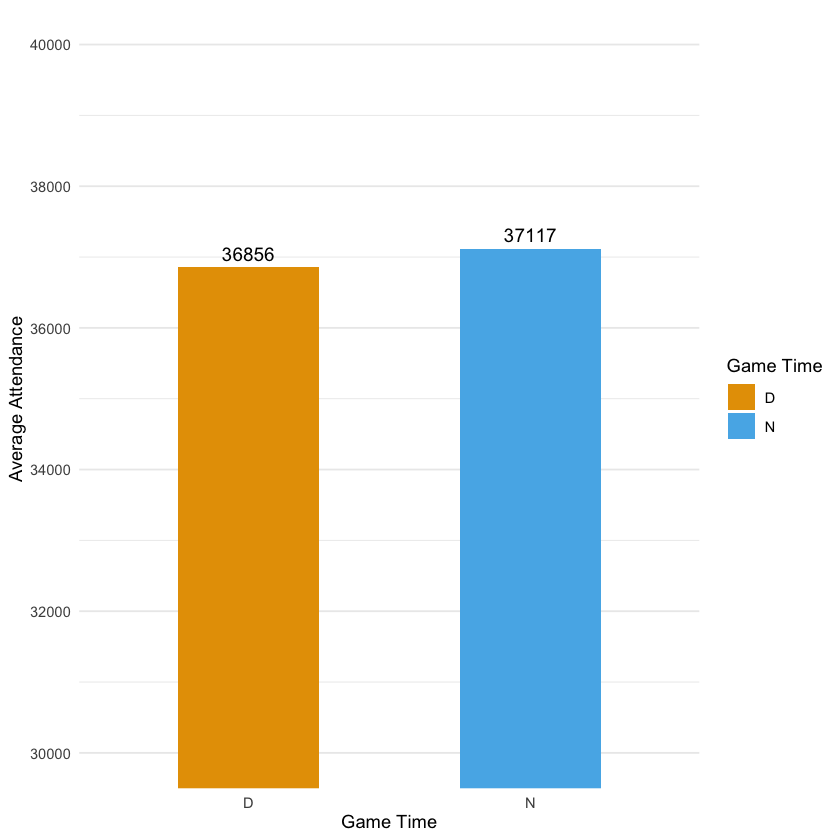

In [6]:
training_sample_2005_2012 |>
  group_by(day_night) |>
  summarise(
    ave_attendance = mean(attendance, na.rm = TRUE),
    n_games = n(),
    .groups = "drop"
  ) |>
  ggplot(aes(x = day_night, y = ave_attendance, fill = day_night)) +
  geom_col(width = 0.5) +
  geom_text(
    aes(label = round(ave_attendance, 0)),
    vjust = -0.5, size = 4, color = "black"
  ) +
  labs(x = "Game Time", y = "Average Attendance", fill = "Game Time") +
  scale_y_continuous(breaks = scales::pretty_breaks(n = 5)) +
  ggokabeito::scale_fill_okabe_ito() +
  coord_cartesian(ylim = c(30000, 40000)) +
  theme_minimal() +
  theme(panel.grid.major.x = element_blank())

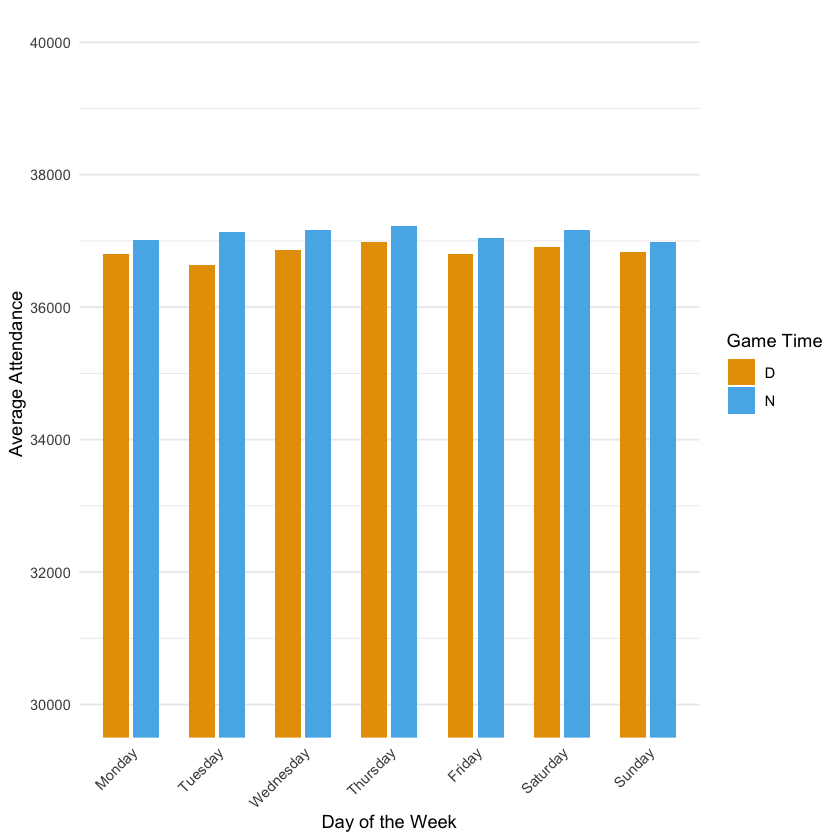

In [7]:
training_sample_2005_2012 |>
  mutate(
    dotw = factor(
      dotw,
      levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")
    )
  ) |>
  group_by(dotw, day_night) |>
  summarise(
    ave_attendance = mean(attendance, na.rm = TRUE),
    n_games = n(),
    .groups = "drop"
  ) |>
  ggplot(aes(x = dotw, y = ave_attendance, fill = day_night)) +
  geom_col(position = position_dodge(width = 0.7), width = 0.6) +
  ggokabeito::scale_fill_okabe_ito(name = "Game Time") +
  labs(x = "Day of the Week", y = "Average Attendance") +
  scale_y_continuous(breaks = scales::pretty_breaks(n = 5)) +
  coord_cartesian(ylim = c(30000, 40000)) +
  theme_minimal() +
  theme(
    panel.grid.major.x = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

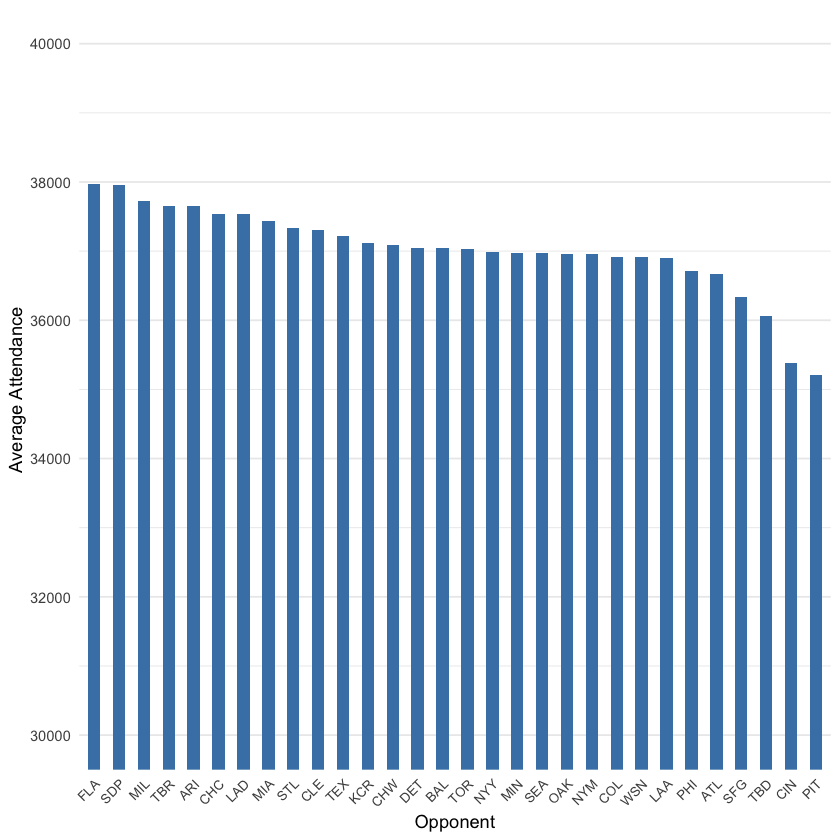

In [8]:
training_sample_2005_2012 |>
  group_by(opp) |>
  summarise(
    ave_attendance = mean(attendance, na.rm = TRUE),
    n_games = n(),
    .groups = "drop"
  ) |>
  arrange(desc(ave_attendance)) |>
  mutate(opp = factor(opp, levels = opp)) |>
  ggplot(aes(x = opp, y = ave_attendance)) +
  geom_col(fill = "steelblue", width = 0.5) +
  labs(x = "Opponent", y = "Average Attendance") +
  scale_y_continuous(breaks = scales::pretty_breaks(n = 5)) +
  coord_cartesian(ylim = c(30000, 40000)) +
  theme_minimal() +
  theme(
    panel.grid.major.x = element_blank(),
    axis.text.x = element_text(size = 8, angle = 45, hjust = 1)
  )

In [9]:
average_attendance_by_daynight <- 
  training_sample_2005_2012 |>
  group_by(day_night) |>
  summarise(
    ave_attendance = mean(attendance, na.rm = TRUE),
    .groups = "drop"
  )

average_attendance_by_dotw_dn <- 
  training_sample_2005_2012 |>
  group_by(dotw, day_night) |>
  summarise(
    ave_attendance = mean(attendance, na.rm = TRUE),
    .groups = "drop"
  )

average_attendance_by_opp <- 
  training_sample_2005_2012 |>
  group_by(opp) |>
  summarise(
    ave_attendance = mean(attendance, na.rm = TRUE),
    .groups = "drop"
  )

test_sample_2013_2015 <- 
  test_sample_2013_2015 |>
  left_join(average_attendance_by_daynight, by = "day_night") |>
  rename(predicted_attendance_daynight = ave_attendance) |>
  left_join(average_attendance_by_dotw_dn, by = c("dotw", "day_night")) |>
  rename(predicted_attendance_dotw_dn = ave_attendance) |>
  left_join(average_attendance_by_opp, by = "opp") |>
  rename(predicted_attendance_opp = ave_attendance)

### Exercise 2

In [10]:
simple_model_errors <- 
  test_sample_2013_2015 |>
  select(
    attendance,
    predicted_attendance_daynight,
    predicted_attendance_dotw_dn,
    predicted_attendance_opp
  ) |>
  pivot_longer(
    cols = starts_with("predicted_attendance_"),
    names_to = "model",
    values_to = "predicted_attendance"
  ) |>
  mutate(
    model = recode(
      model,
      predicted_attendance_daynight = "Day/Night",
      predicted_attendance_dotw_dn = "Day of week x Day/Night",
      predicted_attendance_opp = "Opponent"
    ),
    error            = attendance - predicted_attendance,
    abs_error        = abs(error),
    squared_error    = error ^ 2,
    percentage_error = (error / attendance) * 100
  )

In [11]:
simple_model_metrics <- 
  simple_model_errors |>
  group_by(model) |>
  summarise(
    MAE  = mean(abs_error, na.rm = TRUE),
    RMSE = sqrt(mean(squared_error, na.rm = TRUE)),
    MAPE = mean(abs(percentage_error), na.rm = TRUE),
    .groups = "drop"
  )

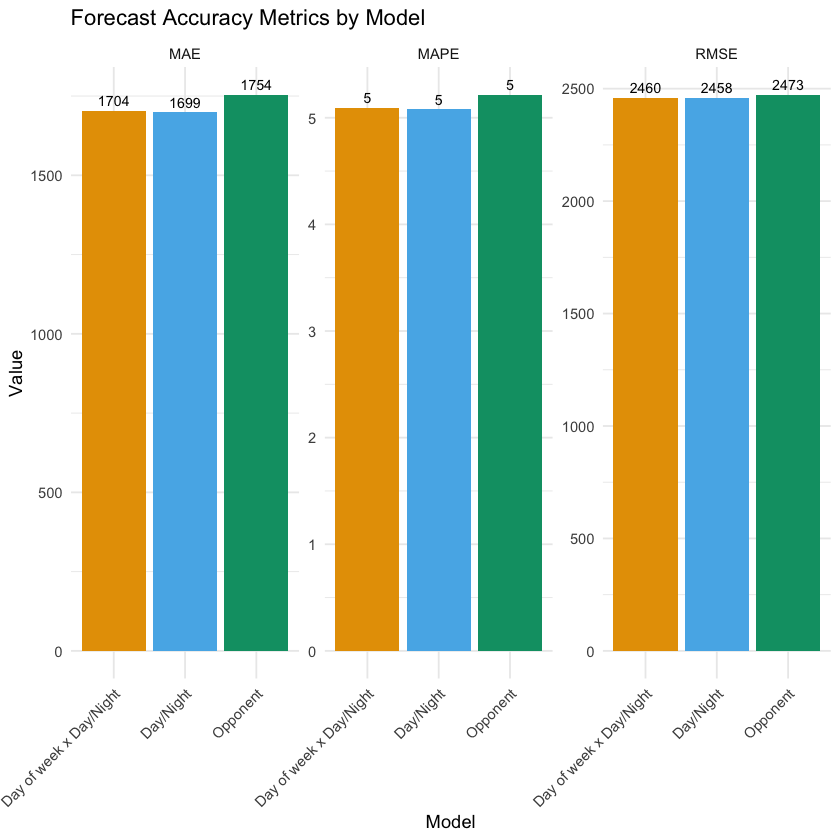

In [12]:
simple_metrics_long <-
  simple_model_metrics |>
  pivot_longer(
    cols = c(MAE, RMSE, MAPE),
    names_to = "metric",
    values_to = "value"
  )

ggplot(simple_metrics_long, aes(x = model, y = value, fill = model)) +
  geom_col() +
  geom_text(aes(label = round(value, 0)), vjust = -0.5, size = 3) +
  facet_wrap(~ metric, scales = "free_y") +
  ggokabeito::scale_fill_okabe_ito() +
  labs(
    title = "Forecast Accuracy Metrics by Model",
    x = "Model",
    y = "Value"
  ) +
  theme_minimal() +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

### Exercise 3

In [13]:
basic_ols_model <- 
  lm(attendance ~ opp + day_night + dotw,
     data = training_sample_2005_2012
  )

In [14]:
summary(basic_ols_model)


Call:
lm(formula = attendance ~ opp + day_night + dotw, data = training_sample_2005_2012)

Residuals:
    Min      1Q  Median      3Q     Max 
-3027.6  -508.3   220.1   668.3  1361.3 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)   37280.07     395.03  94.373  < 2e-16 ***
oppATL         -816.94     454.34  -1.798 0.072655 .  
oppBAL         -480.94     383.22  -1.255 0.209959    
oppCHC          -53.34     637.77  -0.084 0.933372    
oppCHW         -461.19     405.50  -1.137 0.255846    
oppCIN        -2246.51     633.01  -3.549 0.000416 ***
oppCLE         -315.64     398.52  -0.792 0.428659    
oppCOL         -771.82     633.01  -1.219 0.223205    
oppDET         -527.25     402.09  -1.311 0.190259    
oppFLA          283.85     633.01   0.448 0.654019    
oppKCR         -438.18     399.61  -1.097 0.273283    
oppLAA         -676.53     393.45  -1.720 0.086029 .  
oppLAD           31.85     637.39   0.050 0.960166    
oppMIA         -248.82     633

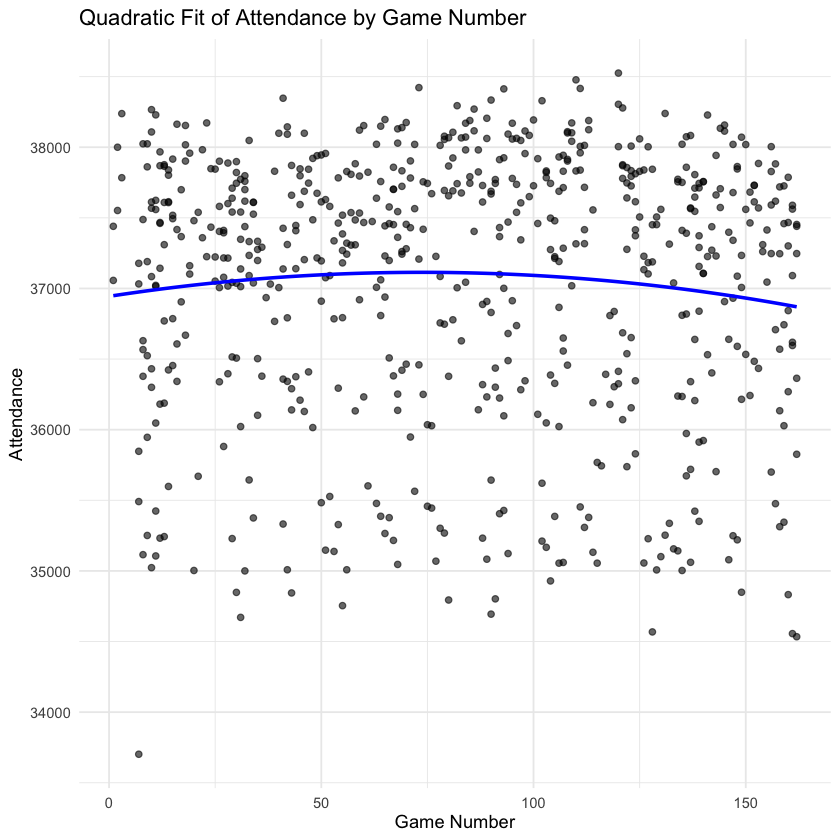

In [15]:
ggplot(training_sample_2005_2012, aes(x = gm, y = attendance)) +
  geom_point(alpha = 0.6) +
  stat_smooth(
    method  = "lm",
    formula = y ~ x + I(x^2),
    color   = "blue",
    se      = FALSE
  ) +
  labs(
    title = "Quadratic Fit of Attendance by Game Number",
    x     = "Game Number",
    y     = "Attendance"
  ) +
  theme_minimal()

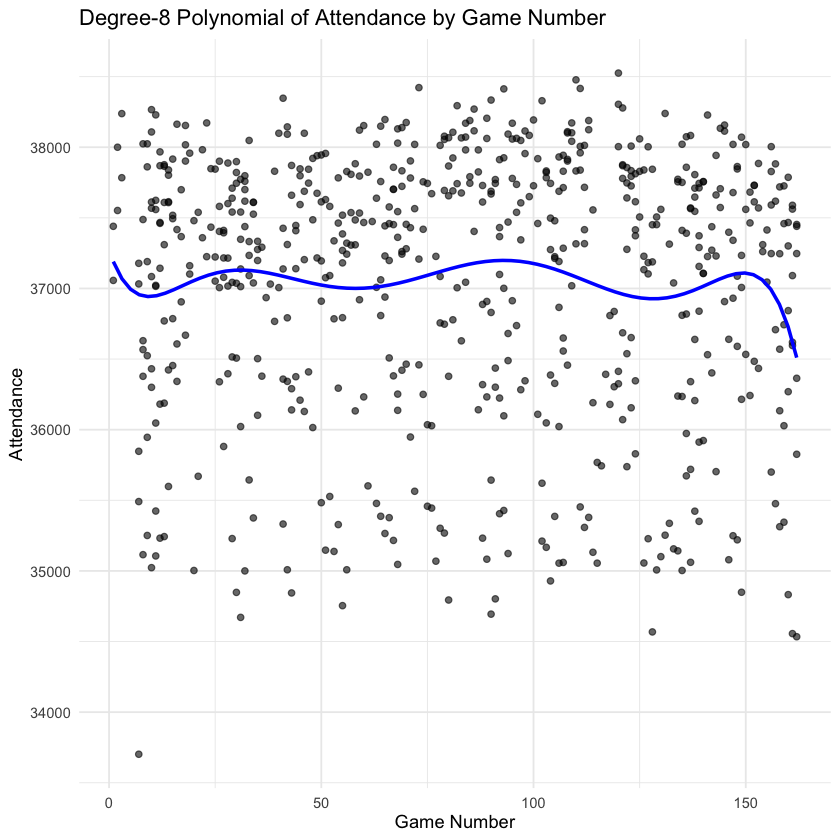

In [16]:
ggplot(training_sample_2005_2012, aes(x = gm, y = attendance)) +
  geom_point(alpha = 0.6) +
  stat_smooth(
    method  = "lm",
    formula = y ~ x + I(x ^ 2) + I(x ^ 3) + I(x ^ 4) + I(x ^ 5) + I(x ^ 6) + I(x ^ 7) + I(x ^ 8),
    color   = "blue",
    se      = FALSE
  ) +
  labs(
    title = "Degree-8 Polynomial of Attendance by Game Number",
    x     = "Game Number",
    y     = "Attendance"
  ) +
  theme_minimal()

In [17]:
non_linear_ols_model <- 
  lm(
    attendance ~ gm + I(gm^2), 
    data = training_sample_2005_2012
  )

eighth_poly_ols_model <- 
  lm(
    attendance ~ opp + day_night + dotw + gm + I(gm^2) + I(gm^3) + I(gm^4) + I(gm^5) + I(gm^6) + I(gm^7) + I(gm^8),
    data = training_sample_2005_2012
  )

In [18]:
ols_fit_summary <- tibble(
  model = c("Basic OLS", "Quadratic game number", "Degree-8 polynomial OLS"),
  r_squared = c(
    summary(basic_ols_model)$r.squared,
    summary(non_linear_ols_model)$r.squared,
    summary(eighth_poly_ols_model)$r.squared
  )
)

ols_fit_summary

model,r_squared
<chr>,<dbl>
Basic OLS,0.165382745
Quadratic game number,0.004871164
Degree-8 polynomial OLS,0.177355647


### Exercise 4

In [19]:
known_opp_levels <- 
  training_sample_2005_2012 |> 
  pull(opp) |> 
  unique()

safe_test_sample <- 
  test_sample_2013_2015 |>
  filter(opp %in% known_opp_levels)

safe_test_sample <-
  safe_test_sample |>
  mutate(
    predicted_attendance_basic_OLS = predict(basic_ols_model, newdata = safe_test_sample),
    predicted_attendance_non_linear_OLS = predict(non_linear_ols_model, newdata = safe_test_sample),
    predicted_attendance_eighth_poly_OLS = predict(eighth_poly_ols_model, newdata = safe_test_sample)
  )

In [20]:
ols_model_errors <- 
  safe_test_sample |>
  select(
    attendance,
    predicted_attendance_basic_OLS,
    predicted_attendance_non_linear_OLS,
    predicted_attendance_eighth_poly_OLS
  ) |>
  pivot_longer(
    cols = starts_with("predicted_attendance_"),
    names_to = "model",
    values_to = "predicted_attendance"
  ) |>
  mutate(
    model = recode(
      model,
      predicted_attendance_basic_OLS = "Basic OLS",
      predicted_attendance_non_linear_OLS = "Quadratic game number",
      predicted_attendance_eighth_poly_OLS = "Degree-8 polynomial OLS"
    ),
    error            = attendance - predicted_attendance,
    abs_error        = abs(error),
    squared_error    = error ^ 2,
    percentage_error = (error / attendance) * 100
  )

In [22]:
ols_model_metrics <- 
  ols_model_errors |>
  group_by(model) |>
  summarise(
    MAE  = mean(abs_error, na.rm = TRUE),
    RMSE = sqrt(mean(squared_error, na.rm = TRUE)),
    MAPE = mean(abs(percentage_error), na.rm = TRUE),
    .groups = "drop"
  ) |>
  arrange(MAE)

ols_model_metrics

model,MAE,RMSE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
Quadratic game number,1673.879,2396.401,4.987384
Degree-8 polynomial OLS,1777.871,2493.439,5.283813
Basic OLS,1781.107,2495.325,5.292389


### Exercise 5

In [23]:
tibble(
  sample = c("Full test sample", "OLS-safe test sample"),
  n_games = c(
    nrow(test_sample_2013_2015),
    nrow(safe_test_sample)
  )
)

test_sample_2013_2015 |>
  filter(!(opp %in% known_opp_levels)) |>
  count(opp, sort = TRUE)

sample,n_games
<chr>,<int>
Full test sample,243
OLS-safe test sample,232


opp,n
<chr>,<int>
HOU,11
